# Module 02 — Prompt Engineering & AI Productivity
**Codomax Digital Solutions · GenAI Internship · Day 6 – Day 10**
**Intern:** Vishva Yadav · B.E. Computer Engineering

| # | Key objective | Section |
|---|---|---|
| 1 | Zero-shot & few-shot prompting, roles, context, instructions, constraints | Part 1 |
| 2 | Structured outputs (JSON) for summarization, classification, generation | Part 2 |
| 3 | AI-assisted coding & debugging; evaluating prompts with templates + testing reports | Parts 3 & 4 |
| 4 | AI Productivity Toolkit: summarization, email, resume, coding, research | Part 5 |

**LLM used:** Google Gemini (free tier) via the `google-genai` SDK.

## 0 · Setup
1. Get a free API key at **aistudio.google.com → Get API key**.
2. In Colab, click the 🔑 **Secrets** icon in the left sidebar → add `GEMINI_API_KEY` → enable *Notebook access*.
3. Run the cells top to bottom. (Free tier has rate limits, so the helper retries automatically.)

💸 **Cost: ₹0.** The Gemini free tier needs no credit card and no billing account, so you can't be charged. If you reach the free limit you just get an error; wait a minute (or until the next day) and re-run.

In [1]:
!pip install -q google-genai pydantic pandas tabulate

In [2]:
import os, json, re, time
import pandas as pd
from pydantic import BaseModel, ValidationError
from google import genai
from google.genai import types

try:
    from google.colab import userdata
    API_KEY = userdata.get("GEMINI_API_KEY")
except Exception:
    API_KEY = os.environ.get("GEMINI_API_KEY")

if not API_KEY:
    raise RuntimeError("GEMINI_API_KEY not found. Add it in Colab → 🔑 Secrets and enable notebook access.")
client = genai.Client(api_key=API_KEY)

# 100% FREE: no billing account is linked, so Google can never charge you.
# If you hit the free limit you just get a "429" error; wait and re-run.
# Auto-pick the first free-tier model that works (Google renames models often).
CANDIDATE_MODELS = ["gemini-flash-latest", "gemini-flash-lite-latest",
                    "gemini-2.5-flash", "gemini-2.5-flash-lite"]
MODEL = None
for m in CANDIDATE_MODELS:
    try:
        client.models.generate_content(model=m, contents="hi")
        MODEL = m
        break
    except Exception as e:
        print(f"{m} not available: {str(e)[:80]}")
if MODEL is None:
    raise RuntimeError("No model worked. Open aistudio.google.com, copy a free model name, "
                       "and put it at the start of CANDIDATE_MODELS.")
print("✅ Using model:", MODEL)

def ask(prompt, system=None, temperature=0.7, json_mode=False, schema=None, retries=3):
    """One helper for every LLM call in this notebook."""
    cfg = {"temperature": temperature}
    if system:
        cfg["system_instruction"] = system
    if json_mode or schema is not None:
        cfg["response_mime_type"] = "application/json"
    if schema is not None:
        cfg["response_schema"] = schema
    for attempt in range(retries):
        try:
            r = client.models.generate_content(
                model=MODEL, contents=prompt,
                config=types.GenerateContentConfig(**cfg))
            return r.text
        except Exception as e:
            if attempt == retries - 1:
                raise
            print(f"Retrying after error: {e}")
            time.sleep(5 * 2 ** attempt)

def show(title, text):
    print(f"\n{'=' * 70}\n{title}\n{'=' * 70}\n{text}")

show("Sanity check", ask("Say hello to a Codomax intern in one short sentence."))

gemini-flash-latest not available: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently exp
✅ Using model: gemini-flash-lite-latest

Sanity check
Welcome to the Codomax team, intern—we're thrilled to have you here!


## Part 1 · Prompting fundamentals

### 1.1 Zero-shot vs few-shot
- **Zero-shot**: give only the instruction. Works for common tasks.
- **Few-shot**: add a handful of solved examples so the model copies the *format* and *decision boundary*.

In [3]:
review = "The delivery was late but honestly the product quality made up for it."

zero_shot = f"""Classify the sentiment of this review as Positive, Negative, or Mixed.
Review: {review}
Sentiment:"""

few_shot = f"""Classify the sentiment of each review as Positive, Negative, or Mixed.
Answer with one word only.

Review: Absolutely love it, works perfectly!
Sentiment: Positive

Review: Broke after two days, waste of money.
Sentiment: Negative

Review: Great screen, but the battery dies by noon.
Sentiment: Mixed

Review: {review}
Sentiment:"""

show("ZERO-SHOT", ask(zero_shot, temperature=0))
show("FEW-SHOT", ask(few_shot, temperature=0))


ZERO-SHOT
Sentiment: Mixed

FEW-SHOT
Mixed


**Observation:** zero-shot often explains its reasoning in a sentence or two. Few-shot replies with exactly one label, because the examples showed it the format.

### 1.2 Prompt anatomy: Role · Context · Instruction · Constraints · Output format
A vague prompt leaves the model guessing. A structured prompt removes ambiguity.

In [4]:
vague = "Write about Python."

structured = """ROLE: You are a friendly programming instructor.
CONTEXT: Your students are first-year engineering students who know basic C.
INSTRUCTION: Explain why Python is popular for AI/ML.
CONSTRAINTS:
- Exactly 3 reasons, each under 25 words.
- Compare with C at least once.
- No code.
OUTPUT FORMAT: A numbered list followed by a one-line takeaway."""

show("VAGUE PROMPT", ask(vague)[:800] + " ...")
show("STRUCTURED PROMPT", ask(structured, temperature=0.4))

Retrying after error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

VAGUE PROMPT
**Python** is one of the world’s most popular, powerful, and versatile programming languages. Created by Guido van Rossum and first released in 1991, Python was designed with a philosophy that emphasizes code readability and simplicity. Its name has nothing to do with the snake—Van Rossum was a fan of the British comedy series *Monty Python's Flying Circus*.

Today, Python powers everything from simple automation scripts to artificial intelligence, space exploration data analysis, and web applications for tech giants like Google, Netflix, and NASA.

Here is a closer look at why Python has become the undisputed king of modern programming.

---

### 1. The Core Philosophy: Readability and Simplicity
Python’s syntax closely resembles the English language, making

### 1.3 System instructions (roles) and temperature
The **system instruction** sets persistent behaviour. **Temperature** controls randomness: about 0 for facts and classification, 0.7 or higher for creative work.

In [5]:
question = "What is a context window in an LLM?"
personas = {
    "Teacher for a 10-year-old": "You explain things to a 10-year-old using a simple analogy. Max 3 sentences.",
    "Senior ML engineer": "You are a senior ML engineer. Be precise and technical. Max 3 sentences.",
}
for name, sys_prompt in personas.items():
    show(f"ROLE: {name}", ask(question, system=sys_prompt, temperature=0.3))

for t in (0.0, 1.2):
    outs = [ask("Suggest a creative name for an AI study-buddy app. Name only.", temperature=t) for _ in range(3)]
    show(f"temperature={t}", "\n".join(o.strip() for o in outs))


ROLE: Teacher for a 10-year-old
Think of an LLM's context window like a sticky note on a whiteboard—it's the only amount of space it has to remember what you were just talking about. If you write too much on that note, the top parts fall off and the AI completely forgets them!

ROLE: Senior ML engineer
The context window is the maximum number of tokens—spanning both input prompts and generated outputs—that a Large Language Model can process and retain in its working memory during a single inference pass. Architecturally constrained by positional embeddings and quadratic self-attention complexity, exceeding this limit results in truncation and catastrophic forgetting of earlier text. Modern models expand this boundary using linear attention approximations, sparse retrieval, or recurrent state-space mechanisms.

temperature=0.0
Synapse
CogniPrep
CortexCollab

temperature=1.2
Synapse
Synapse
Synapse


## Part 2 · Structured outputs (JSON)
Applications need machine-readable output. Two techniques:
1. **JSON mode** (`response_mime_type="application/json"`) plus a schema described in the prompt.
2. **Schema-enforced output**: pass a Pydantic model as `response_schema`, then **validate** the result in Python.

### 2.1 Summarization → JSON

In [6]:
article = """Codomax Digital Solutions launched a 30-day Generative AI internship in 2026.
Interns complete weekly modules covering GenAI foundations, prompt engineering, RAG and
AI agents. Each module requires a GitHub repository, a Colab notebook and a LinkedIn post.
Top performers are eligible for placement opportunities ranging from 8 to 36 LPA.
Mentors review submissions within 48 hours and award stars for quality work."""

class ArticleSummary(BaseModel):
    title: str
    one_line_summary: str
    key_points: list[str]
    entities: list[str]
    numbers_mentioned: list[str]

raw = ask(f"Summarize this article.\n\n{article}", schema=ArticleSummary, temperature=0)
summary = ArticleSummary.model_validate_json(raw)   # raises if the JSON is malformed
print(json.dumps(summary.model_dump(), indent=2))

Retrying after error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
{
  "title": "Codomax Digital Solutions Generative AI Internship",
  "one_line_summary": "Codomax Digital Solutions launched a 30-day Generative AI internship featuring weekly modules, practical projects, and placement opportunities for top performers.",
  "key_points": [
    "The internship lasts for 30 days and focuses on Generative AI.",
    "Weekly modules cover foundations, prompt engineering, RAG, and AI agents.",
    "Deliverables for each module include a GitHub repo, a Colab notebook, and a LinkedIn post.",
    "Top performers receive placement opportunities ranging from 8 to 36 LPA.",
    "Mentors review submissions within 48 hours and award stars for quality."
  ],
  "entities": [
    "Codomax Digital Solutions",
    "GitHub",
    "Colab",
    "LinkedIn"
  ],
  

### 2.2 Classification → JSON (support-ticket triage)

In [7]:
CATEGORIES = ["Billing", "Technical", "Account", "Feedback"]
PRIORITIES = ["Low", "Medium", "High"]

class Ticket(BaseModel):
    category: str
    priority: str
    sentiment: str
    summary: str
    suggested_reply: str

tickets = [
    "I was charged twice for my subscription this month. Please refund ASAP!",
    "The app crashes every time I upload a PDF larger than 5MB.",
    "Just wanted to say the new dashboard design looks amazing.",
]

triage_prompt = """You are a support triage assistant.
Classify the ticket. category must be one of {cats}. priority must be one of {pris}.
sentiment must be Positive, Neutral or Negative. summary <= 15 words.
suggested_reply <= 40 words, polite.

Ticket: {ticket}"""

rows = []
for t in tickets:
    raw = ask(triage_prompt.format(cats=CATEGORIES, pris=PRIORITIES, ticket=t),
              schema=Ticket, temperature=0)
    tk = Ticket.model_validate_json(raw)
    assert tk.category in CATEGORIES, f"Invalid category: {tk.category}"
    rows.append({"ticket": t[:50] + "...", **tk.model_dump()})

pd.DataFrame(rows)

,ticket,category,priority,sentiment,summary,suggested_reply
0,I was charged twice for my subscription this m...,Billing,High,Negative,Customer charged twice for subscription this m...,We sincerely apologize for the duplicate charg...
1,The app crashes every time I upload a PDF larg...,Technical,High,Negative,App crashes when uploading PDFs larger than 5MB.,We are sorry for the trouble. Our technical te...
2,Just wanted to say the new dashboard design lo...,Feedback,Low,Positive,Customer complimented the new dashboard design.,Thank you so much for your kind words! We are ...


### 2.3 Generation → JSON (structured content creation)

In [8]:
gen_prompt = """Create a 3-question multiple-choice quiz on "tokens and context windows in LLMs".
Return JSON: {"topic": str, "questions": [{"question": str, "options": [4 strings],
"answer": str, "explanation": str}]}. The answer must exactly match one option."""

quiz = json.loads(ask(gen_prompt, json_mode=True, temperature=0.5))
for i, q in enumerate(quiz["questions"], 1):
    print(f"Q{i}. {q['question']}")
    for o in q["options"]:
        print("   -", o)
    print("   ✅", q["answer"], "|", q["explanation"], "\n")
    assert q["answer"] in q["options"], "Answer not in options!"

Q1. What is a token in the context of Large Language Models?
   - A single word always equal to 4 bytes
   - A chunk of text, which can be a word, part of a word, or punctuation
   - A security credential used to access the API
   - An image pixel processed by the model
   ✅ A chunk of text, which can be a word, part of a word, or punctuation | Tokens are the basic units of text that an LLM processes, which are generated by tokenizers and often represent sub-words rather than whole words. 

Q2. What does the 'context window' of an LLM refer to?
   - The physical screen size of the user interface
   - The total amount of training data used to build the model
   - The maximum number of tokens the model can process in a single prompt and response
   - The time limit allowed for generating a response
   ✅ The maximum number of tokens the model can process in a single prompt and response | The context window defines the limits of short-term memory for the LLM, including both the input conte

## Part 3 · AI-assisted coding & debugging
Workflow: **give the AI buggy code → get a structured diagnosis and fix → verify with our OWN tests.**
Never trust AI-generated code until it has been tested.

In [9]:
buggy_code = """
def average_scores(scores):
    total = 0
    for i in range(1, len(scores)):
        total += scores[i]
    return total / len(scores)

def top_student(students):
    best = students[0]
    for s in students:
        if s["score"] < best["score"]:
            best = s
    return best["name"]
"""

debug_prompt = f"""ROLE: You are a senior Python engineer and code reviewer.
INSTRUCTION: Find every bug and unhandled edge case in the code, then fix it.
CONSTRAINTS: Keep function names and signatures the same. average_scores([]) should return 0.
top_student([]) should return None.
OUTPUT FORMAT: JSON with keys "bugs" (list of strings), "fixed_code" (string),
"tests" (list of Python assert statements).

CODE:
```python
{buggy_code}
```"""

result = json.loads(ask(debug_prompt, json_mode=True, temperature=0))
print("🐞 Bugs found:")
for b in result["bugs"]:
    print(" -", b)
print("\n🔧 Fixed code:\n", result["fixed_code"])

🐞 Bugs found:
 - average_scores uses range(1, len(scores)) which skips the first element at index 0.
 - average_scores does not handle an empty list, causing a ZeroDivisionError.
 - top_student assumes the list is non-empty, causing an IndexError if passed an empty list.
 - top_student looks for the minimum score using '<' instead of the maximum score using '>' for finding the top student.
 - top_student returns only the 'name' string, but should return the student name safely considering empty inputs.

🔧 Fixed code:
 def average_scores(scores):
    if not scores:
        return 0
    total = sum(scores)
    return total / len(scores)

def top_student(students):
    if not students:
        return None
    best = students[0]
    for s in students:
        if s.get("score", 0) > best.get("score", 0):
            best = s
    return best.get("name")


In [10]:
# Verify the AI fix with OUR test cases (review the code above before executing it)
ns = {}
exec(result["fixed_code"], ns)
avg, top = ns["average_scores"], ns["top_student"]

our_tests = {
    "avg normal":   lambda: avg([80, 90, 100]) == 90,
    "avg single":   lambda: avg([50]) == 50,
    "avg empty":    lambda: avg([]) == 0,
    "top normal":   lambda: top([{"name": "A", "score": 70}, {"name": "B", "score": 95}]) == "B",
    "top empty":    lambda: top([]) is None,
}
for name, test in our_tests.items():
    try:
        print(("✅" if test() else "❌"), name)
    except Exception as e:
        print("❌", name, "->", type(e).__name__, e)

# Bonus: also run the AI-written tests
passed = 0
for t in result["tests"]:
    try:
        exec(t, ns); passed += 1
    except Exception:
        print("AI test failed:", t)
print(f"\nAI-generated tests passed: {passed}/{len(result['tests'])}")

✅ avg normal
✅ avg single
✅ avg empty
✅ top normal
✅ top empty

AI-generated tests passed: 4/4


### 3.1 Code generation with constraints

In [11]:
gen_code_prompt = """Write a Python function `is_valid_email(email: str) -> bool` using only the `re` module.
Constraints: one function, a docstring, no external libraries, no explanation.
Return ONLY the code, no markdown fences."""

code_out = ask(gen_code_prompt, temperature=0)
code_out = re.sub(r"^```(?:python)?|```$", "", code_out.strip(), flags=re.M).strip()
print(code_out)

ns2 = {}
exec(code_out, ns2)
f = ns2["is_valid_email"]
cases = {"vishva@gmail.com": True, "a.b@codomax.in": True, "bad@": False, "no-at.com": False, "": False}
for email, exp in cases.items():
    print(("✅" if f(email) == exp else "❌"), repr(email), "->", f(email))

import re

def is_valid_email(email: str) -> bool:
    """Check if a string is a valid email address using regular expressions."""
    pattern = r"^[a-zA-Z0-9_.+-]+@[a-zA-Z0-9-]+\.[a-zA-Z0-9-.]+$"
    return bool(re.match(pattern, email))
✅ 'vishva@gmail.com' -> True
✅ 'a.b@codomax.in' -> True
✅ 'bad@' -> False
✅ 'no-at.com' -> False
✅ '' -> False


## Part 4 · Prompt evaluation with reusable templates + testing report
Instead of judging prompts by feel, we **measure** them:
1. Build a reusable `PromptTemplate` class.
2. Create a labelled **test set**.
3. Run several prompt versions on the same test set.
4. Score them: accuracy, valid-format rate, latency.
5. Export a **testing report** (Markdown) to commit to GitHub.

In [12]:
class PromptTemplate:
    """A reusable, versioned prompt with placeholders like {text}."""
    def __init__(self, name, template, system=None, temperature=0.0, json_mode=False):
        self.name, self.template, self.system = name, template, system
        self.temperature, self.json_mode = temperature, json_mode

    def render(self, **kwargs):
        return self.template.format(**kwargs)

    def run(self, **kwargs):
        return ask(self.render(**kwargs), system=self.system,
                   temperature=self.temperature, json_mode=self.json_mode)

LABELS = ["Billing", "Technical", "Account", "Feedback"]

TEST_SET = [
    ("I was charged twice this month, please refund.", "Billing"),
    ("My invoice shows the wrong GST number.", "Billing"),
    ("The page keeps showing a 500 error when I submit my notebook.", "Technical"),
    ("Colab link upload button does nothing on Safari.", "Technical"),
    ("I forgot my password and the reset email never arrives.", "Account"),
    ("How do I change the email address on my profile?", "Account"),
    ("Loved the workshop on prompt engineering, very helpful!", "Feedback"),
    ("It would be nice to have a dark mode on the dashboard.", "Feedback"),
    ("Payment failed but money was debited from my bank.", "Billing"),
    ("I can't log in after changing my phone number.", "Account"),
]

In [13]:
V1_ZERO_SHOT = PromptTemplate(
    "v1_zero_shot_vague",
    "What kind of customer message is this?\n\n{text}",
    temperature=0.0)

V2_ZERO_SHOT_CONSTRAINED = PromptTemplate(
    "v2_zero_shot_constrained",
    """Classify the customer message into exactly one category: Billing, Technical, Account, Feedback.
Reply with the category name only.

Message: {text}""",
    temperature=0.0)

V3_FEW_SHOT_JSON = PromptTemplate(
    "v3_role_few_shot_json",
    """Classify the customer message.

Categories:
- Billing: payments, refunds, invoices, charges
- Technical: bugs, errors, crashes, things not working
- Account: login, password, profile, personal details
- Feedback: praise, complaints about experience, feature requests

Examples:
"Refund not received yet" -> {{"category": "Billing", "confidence": 0.95}}
"App freezes on startup" -> {{"category": "Technical", "confidence": 0.9}}
"Update my phone number" -> {{"category": "Account", "confidence": 0.9}}

Message: "{text}"
Return JSON: {{"category": <one category>, "confidence": <0-1>}}""",
    system="You are a precise customer-support triage system.",
    temperature=0.0, json_mode=True)

TEMPLATES = [V1_ZERO_SHOT, V2_ZERO_SHOT_CONSTRAINED, V3_FEW_SHOT_JSON]

def parse_label(output, template):
    """Returns (label, format_ok)."""
    if template.json_mode:
        try:
            label = json.loads(output)["category"]
            return label, label in LABELS
        except Exception:
            return None, False
    clean = output.strip().strip(".").strip()
    if clean in LABELS:
        return clean, True                  # exact format followed
    found = [l for l in LABELS if l.lower() in output.lower()]
    return (found[0] if found else None), False

In [14]:
results = []
for tmpl in TEMPLATES:
    for text, expected in TEST_SET:
        t0 = time.time()
        out = tmpl.run(text=text)
        latency = time.time() - t0
        label, fmt_ok = parse_label(out, tmpl)
        results.append({
            "prompt": tmpl.name, "input": text, "expected": expected,
            "predicted": label, "correct": label == expected,
            "format_ok": fmt_ok, "latency_s": round(latency, 2),
            "raw_output": out.strip()[:120],
        })
        time.sleep(4)   # stay within free-tier rate limits (~15 requests/min)

df = pd.DataFrame(results)
summary_df = (df.groupby("prompt", sort=False)
                .agg(accuracy=("correct", "mean"),
                     format_compliance=("format_ok", "mean"),
                     avg_latency_s=("latency_s", "mean"))
                .round(2))
summary_df

,accuracy,format_compliance,avg_latency_s
prompt,,,
v1_zero_shot_vague,0.8,0.0,5.75
v2_zero_shot_constrained,0.9,1.0,5.71
v3_role_few_shot_json,1.0,1.0,3.87


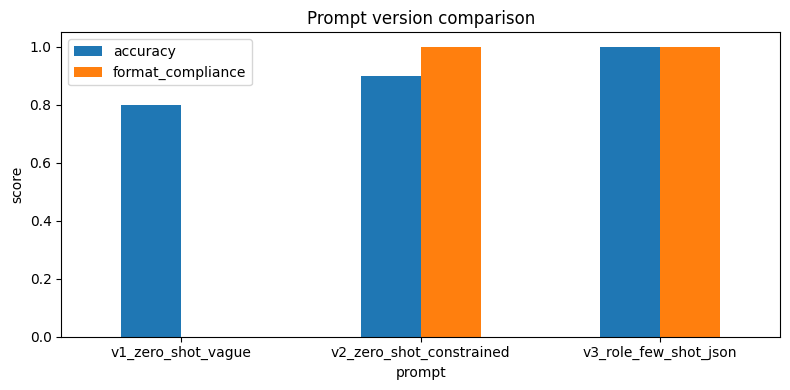

,prompt,input,expected,predicted,raw_output
0,v1_zero_shot_vague,"I was charged twice this month, please refund.",Billing,Billing,This is a **Billing / Payment Dispute** custom...
1,v1_zero_shot_vague,My invoice shows the wrong GST number.,Billing,Billing,This is a **billing / invoice correction** req...
2,v1_zero_shot_vague,The page keeps showing a 500 error when I subm...,Technical,Technical,This is a **Technical Support Request** (speci...
3,v1_zero_shot_vague,Colab link upload button does nothing on Safari.,Technical,Technical,"This is a **bug report** (specifically, a tech..."
4,v1_zero_shot_vague,I forgot my password and the reset email never...,Account,Technical,This is a **Technical Support** request (speci...
5,v1_zero_shot_vague,How do I change the email address on my profile?,Account,Account,This is a **How-To / Instructional Support Req...
6,v1_zero_shot_vague,"Loved the workshop on prompt engineering, very...",Feedback,Feedback,This customer message is a **positive feedback...
7,v1_zero_shot_vague,It would be nice to have a dark mode on the da...,Feedback,None,This customer message is a **Feature Request**...
8,v1_zero_shot_vague,Payment failed but money was debited from my b...,Billing,Billing,This is a **Billing / Payment Dispute** or **T...
9,v1_zero_shot_vague,I can't log in after changing my phone number.,Account,Account,This customer message can be classified in a f...


In [15]:
import matplotlib.pyplot as plt
ax = summary_df[["accuracy", "format_compliance"]].plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylim(0, 1.05); ax.set_ylabel("score"); ax.set_title("Prompt version comparison")
plt.tight_layout(); plt.show()

# Show failures for analysis
df[~df["correct"] | ~df["format_ok"]][["prompt", "input", "expected", "predicted", "raw_output"]]

In [16]:
# ---- Generate the testing report (commit reports/prompt_evaluation_report.md to GitHub)
os.makedirs("reports", exist_ok=True)
best = summary_df.sort_values(["accuracy", "format_compliance"], ascending=False).index[0]

lines = [
    "# Prompt Evaluation Report: Support-Ticket Classification",
    f"*Model:* `{MODEL}` · *Test cases:* {len(TEST_SET)} · *Generated:* {time.strftime('%Y-%m-%d %H:%M')}",
    "",
    "## Prompt versions tested",
]
for t in TEMPLATES:
    lines += [f"### `{t.name}`", "```", t.template, "```", ""]
lines += ["## Results", summary_df.to_markdown(), "",
          f"**Best prompt:** `{best}`", "",
          "## Failures"]
fails = df[~df["correct"] | ~df["format_ok"]]
lines.append(fails[["prompt", "input", "expected", "predicted", "raw_output"]].to_markdown(index=False)
             if len(fails) else "No failures.")
lines += ["", "## Observations",
          "- **v1 (vague)**: the model answers in free text, so it is hard to parse and its format compliance is low.",
          "- **v2 (constrained)**: listing the allowed labels and saying 'category only' fixes most format issues.",
          "- **v3 (role + definitions + few-shot + JSON)**: category definitions settle ambiguous cases (e.g. login vs bug), and JSON output can be parsed reliably.",
          "", "## Conclusion",
          "Explicit constraints and output formats matter more than clever wording. "
          "Few-shot examples and category definitions improve consistency on edge cases. "
          "Always evaluate prompts on a fixed test set before using them in an application."]

report = "\n".join(lines)
with open("reports/prompt_evaluation_report.md", "w") as fh:
    fh.write(report)
print(report[:1500], "...\n\n✅ Saved reports/prompt_evaluation_report.md")

# Prompt Evaluation Report: Support-Ticket Classification
*Model:* `gemini-flash-lite-latest` · *Test cases:* 10 · *Generated:* 2026-11-18 13:16

## Prompt versions tested
### `v1_zero_shot_vague`
```
What kind of customer message is this?

{text}
```

### `v2_zero_shot_constrained`
```
Classify the customer message into exactly one category: Billing, Technical, Account, Feedback.
Reply with the category name only.

Message: {text}
```

### `v3_role_few_shot_json`
```
Classify the customer message.

Categories:
- Billing: payments, refunds, invoices, charges
- Technical: bugs, errors, crashes, things not working
- Account: login, password, profile, personal details
- Feedback: praise, complaints about experience, feature requests

Examples:
"Refund not received yet" -> {{"category": "Billing", "confidence": 0.95}}
"App freezes on startup" -> {{"category": "Technical", "confidence": 0.9}}
"Update my phone number" -> {{"category": "Account", "confidence": 0.9}}

Message: "{text}"
Return 

## Part 5 · AI Productivity Toolkit 🧰
Five reusable workflows built from the same prompt anatomy (Role → Context → Instruction → Constraints → Output).
The same code is in `toolkit/ai_toolkit.py` in the GitHub repo.

In [17]:
# --------------------------------------------------------------------------- #
# Prompt templates                                                            #
# --------------------------------------------------------------------------- #

SUMMARY_STYLES = {
    "bullets": "5 concise bullet points, each under 20 words",
    "tldr": "a single TL;DR sentence under 30 words",
    "executive": "an executive summary: 1 headline, 3 key points, 1 recommended action",
}

SUMMARIZE_TMPL = """ROLE: You are an expert analyst who writes clear, faithful summaries.
CONTEXT: The reader is busy and needs the key information quickly.
INSTRUCTION: Summarize the text below as {style}.
CONSTRAINTS:
- Use only facts present in the text; do not add outside information.
- Keep numbers, names and dates exactly as written.
OUTPUT FORMAT: Plain text only.

TEXT:
\"\"\"{text}\"\"\""""

EMAIL_TMPL = """ROLE: You are a professional business communication assistant.
CONTEXT: Sender: {sender}. Recipient: {recipient}. Purpose: {purpose}.
INSTRUCTION: Write an email that covers every key point below.
KEY POINTS:
{points}
CONSTRAINTS:
- Tone: {tone}. Under {max_words} words.
- Clear subject line, short paragraphs, one explicit call-to-action.
OUTPUT FORMAT: JSON with keys "subject" and "body"."""

RESUME_TMPL = """ROLE: You are a senior technical recruiter and resume coach.
CONTEXT: Target role: {role}.
INSTRUCTION: Rewrite each resume bullet using the formula
Action verb + What you did + Tool/Skill + Measurable result.
CONSTRAINTS:
- Do not invent numbers. If a metric is missing, insert a placeholder like [X%].
- One line per bullet, under 25 words.
OUTPUT FORMAT: JSON list of objects with keys "original", "improved", "why".

BULLETS:
{bullets}"""

CODE_TMPL = """ROLE: You are a senior {language} engineer and patient mentor.
INSTRUCTION: {task_instruction}
CONSTRAINTS:
- Be specific: reference line numbers or variable names.
- Keep the fix minimal; do not rewrite unrelated code.
OUTPUT FORMAT: JSON with keys "summary", "issues" (list of strings),
"fixed_code" (string, empty if not applicable), "tests" (list of assert statements).

CODE:
```{language}
{code}
```"""

CODE_TASKS = {
    "explain": "Explain what the code does, step by step, for a beginner.",
    "debug": "Find every bug or edge case that will fail, then provide corrected code.",
    "review": "Review the code for readability, performance and best practices.",
}

RESEARCH_TMPL = """ROLE: You are a research assistant for a {audience}.
INSTRUCTION: Create a research brief on: "{topic}".
CONSTRAINTS:
- Separate well-established facts from open questions.
- Flag anything that may be outdated or needs verification.
- Do not fabricate citations; suggest what kinds of sources to check instead.
OUTPUT FORMAT: JSON with keys "overview" (string), "key_concepts" (list),
"open_questions" (list), "suggested_sources" (list), "next_steps" (list)."""


# --------------------------------------------------------------------------- #
# Tools                                                                       #
# --------------------------------------------------------------------------- #

def summarize(text: str, style: str = "bullets") -> str:
    style_desc = SUMMARY_STYLES.get(style, style)
    return ask(SUMMARIZE_TMPL.format(style=style_desc, text=text), temperature=0.2)


def draft_email(points: list[str], purpose: str, recipient: str = "the team",
                sender: str = "me", tone: str = "professional and friendly",
                max_words: int = 150) -> dict:
    prompt = EMAIL_TMPL.format(
        sender=sender, recipient=recipient, purpose=purpose, tone=tone,
        max_words=max_words, points="\n".join(f"- {p}" for p in points),
    )
    return json.loads(ask(prompt, temperature=0.5, json_mode=True))


def improve_resume(bullets: list[str], role: str = "Software Engineer Intern") -> list[dict]:
    prompt = RESUME_TMPL.format(role=role, bullets="\n".join(f"- {b}" for b in bullets))
    return json.loads(ask(prompt, temperature=0.4, json_mode=True))


def code_helper(code: str, task: str = "debug", language: str = "python") -> dict:
    prompt = CODE_TMPL.format(language=language, code=code,
                              task_instruction=CODE_TASKS.get(task, task))
    return json.loads(ask(prompt, temperature=0.1, json_mode=True))


def research_brief(topic: str, audience: str = "computer engineering student") -> dict:
    prompt = RESEARCH_TMPL.format(topic=topic, audience=audience)
    return json.loads(ask(prompt, temperature=0.3, json_mode=True))

### 5.1 Summarization

In [18]:
long_text = """Large Language Models (LLMs) are neural networks trained on massive text corpora to
predict the next token. Their capabilities include drafting text, translating, summarizing and
writing code. However, they have a fixed context window, typically measured in tokens, which limits
how much information they can consider at once. LLMs can also hallucinate — generate fluent but
incorrect statements — so outputs in high-stakes domains must be verified. Techniques like prompt
engineering, retrieval-augmented generation (RAG) and fine-tuning help adapt LLMs to specific tasks.
Responsible use also requires attention to bias, privacy and transparency."""

for style in ["tldr", "bullets", "executive"]:
    show(f"Summary style: {style}", summarize(long_text, style))


Summary style: tldr
LLMs are neural networks trained on massive text corpora with capabilities like drafting and summarizing, but they face limitations such as fixed context windows and hallucinations.

Summary style: bullets
- LLMs are neural networks trained on massive text corpora to predict the next token.
- Capabilities include drafting text, translating, summarizing, and writing code.
- Fixed context windows limit the amount of information LLMs can consider at once.
- LLMs can hallucinate, requiring verification of outputs in high-stakes domains.
- Prompt engineering, RAG, fine-tuning, and addressing bias, privacy, and transparency ensure responsible use.

Summary style: executive
HEADLINE: Capabilities, Limitations, and Management of Large Language Models

KEY POINTS:
- Large Language Models are neural networks trained on massive text corpora to predict the next token, enabling tasks like text drafting, translation, summarization, and coding.
- They possess a fixed context wind

### 5.2 Email writer

In [19]:
email = draft_email(
    points=["Module 02 deliverables are submitted",
            "GitHub repo and Colab notebook links attached",
            "Requesting feedback before Module 03 starts"],
    purpose="Inform mentor about Module 02 submission",
    recipient="Codomax internship mentor",
    sender="Vishva Yadav, GenAI Intern")
show("Subject: " + email["subject"], email["body"])

Retrying after error: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

Subject: Module 02 Submission - Vishva Yadav
Hi,

I hope you're having a great week.

I am writing to let you know that I have completed and submitted all the deliverables for Module 02. For your review, I have attached the links to both the GitHub repository and the Google Colab notebook.

Could you please review my work and share your feedback before I officially start working on Module 03?

Thank you for your guidance and support!

Best regards,

Vishva Yadav
GenAI Intern


### 5.3 Resume bullet improver

In [20]:
improved = improve_resume([
    "Did a project on prompt engineering",
    "Made a chatbot using python",
    "Worked in team for college fest website",
], role="Generative AI Intern")
pd.DataFrame(improved)

,original,improved,why
0,Did a project on prompt engineering,Engineered advanced LLM prompts using LangChai...,Replaced vague description with specific actio...
1,Made a chatbot using python,Developed an interactive conversational chatbo...,Added technical stack details and an impact pl...
2,Worked in team for college fest website,Collaborated with a 5-member team to build the...,"Quantified team size, specified the technology..."


### 5.4 Coding assistant

In [21]:
snippet = """
def find_duplicates(nums):
    dups = []
    for i in range(len(nums)):
        for j in range(len(nums)):
            if nums[i] == nums[j] and nums[i] not in dups:
                dups.append(nums[i])
    return dups
"""
review = code_helper(snippet, task="debug")
show("Summary", review["summary"])
show("Issues", "\n".join("- " + i for i in review["issues"]))
show("Fixed code", review["fixed_code"])


Summary
The original function has $O(n^3)$ time complexity due to nested loops and the 'not in dups' check, and it mistakenly identifies every element as its own duplicate because it compares an element at index i with itself at index j (when i == j).

Issues
- Line 5: 'nums[i] == nums[j]' compares an element with itself when i == j, causing every element to be incorrectly added to the duplicates list.
- Line 5: Checking 'nums[i] not in dups' inside nested loops leads to an inefficient $O(n^3)$ time complexity and fails to properly handle lists with multiple duplicate groups or types.
- The use of nested loops for finding duplicates is non-idiomatic and inefficient for large lists.

Fixed code
def find_duplicates(nums):
    seen = set()
    dups = set()
    for num in nums:
        if num in seen:
            dups.add(num)
        else:
            seen.add(num)
    return list(dups)


### 5.5 Research assistant

In [22]:
brief = research_brief("Retrieval-Augmented Generation (RAG) vs fine-tuning")
show("Overview", brief["overview"])
for key in ["key_concepts", "open_questions", "suggested_sources", "next_steps"]:
    show(key.replace("_", " ").title(), "\n".join("- " + str(x) for x in brief[key]))


Overview
Retrieval-Augmented Generation (RAG) and model fine-tuning are two primary methodologies for adapting Large Language Models (LLMs) to specialized domains or private data. RAG dynamically retrieves relevant external documents at inference time and injects them into the model's prompt, making it highly effective for factual accuracy and dynamic knowledge updates. Fine-tuning adjusts the model's internal weights using a specialized dataset, altering its behavior, style, or deep-domain understanding. Current engineering practices often evaluate them based on cost, latency, update frequency, and hallucination mitigation.

Key Concepts
- Retrieval-Augmented Generation (RAG): Combining an external retriever and a vector database with an LLM to ground generated responses in factual documents.
- Fine-tuning: Modifying model weights via supervised learning on a curated dataset to instill domain-specific terminology, formatting, or reasoning patterns.
- Context Window Limitations: The c

## Key learnings
1. **Structure beats wording.** A role, context, explicit constraints and an output format make results consistent.
2. **Few-shot examples teach format and edge cases** more reliably than longer instructions.
3. **Structured output (JSON + Pydantic) turns an LLM into a reliable software component.**
4. **Always verify AI code with your own tests.** AI-written tests can share the same blind spots as AI-written code.
5. **Evaluate prompts like code:** fixed test set, versioned templates, measurable metrics, a written report.
6. **Low temperature** for classification, extraction and code; **higher temperature** for creative generation.

In [23]:
# Optional: download the testing report from Colab
try:
    from google.colab import files
    files.download("reports/prompt_evaluation_report.md")
except Exception:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>